# Machine Learning 2026
# Assignment 1
# Question 3: Regression
**Max Marks: 40**

## Instructions

- Keep collaborations at high level discussions. Copying or plagiarism will be dealt with strictly.
- Rename the notebook with your roll number before submitting. If your roll number is `2024000`, the file must be named `2024000_q3.ipynb`.
- Write code only in the sections marked `# YOUR CODE HERE`. You can NOT write code anywhere else.
- Extract `Q3_DATA.zip` next to the notebook.
- Seed every random operation with your roll number.
- Do not modify any function or class definition outside a `# YOUR CODE HERE` region.
- Do not add or delete cells, even empty ones.
- Do not import any library beyond what is already provided. Every part is solvable without one.
- Submit a single zip file, `Roll_Number_q3.zip`, containing your notebook and a single PDF report.
- Your notebook is re-run after the deadline on data it has not seen. If it fails to run top to bottom, no compensation will be given.
- Notebook parts are graded by re-running your code. Report parts are graded by hand, and are where you justify the choices you made in the notebook.

In [1]:
# =======================
# DO NOT MODIFY THIS CELL
# =======================

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

PATH_TO_DATA_DIR = "./Q3_DATA"
PATH_TO_TRAIN_FILE = os.path.join(PATH_TO_DATA_DIR, "train.csv")

TARGET_COLUMN = "target"
GROUP_COLUMN = "group_id"
ID_COLUMN = "row_id"

In [2]:
# Set this to your roll number as an integer. Example: 2024000
ROLL_NUMBER = None
# YOUR CODE HERE
ROLL_NUMBER = 2024090


## 1. (1 point) Data Loading

(a) **[1 point]** Load the raw training data so it is ready to explore.

In [3]:
def load_raw_data(path):
    """
    Load the raw training data.

    Args:
        path (str): Path to the training CSV file.

    Returns:
        pd.DataFrame: The raw data, exactly as it appears in the file.
    """
    raw = None
    # YOUR CODE HERE
    # Read the CSV as it is; preprocessing happens later.
    raw = pd.read_csv(path)
    return raw

In [4]:
# =======================
# DO NOT MODIFY THIS CELL
# =======================

raw_df = load_raw_data(PATH_TO_TRAIN_FILE)
assert raw_df is not None and len(raw_df) > 0, "load_raw_data() did not return a non-empty DataFrame"
print(f"raw_df: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")

raw_df: 873 rows, 22 columns


## 2. (4 points) Exploratory Data Analysis

(a) Explore the raw data. Look at what
kind of features you have, missing values, the target. Put your EDA analysis plots
and tables that mattered in your report. (You would have to justify your choices.)

**Grading:** both parts are graded from your report. Nothing in this
notebook is scored for Question 2 -- this cell is where you explore, freely.

Data shape: (873, 22)
Unique groups: 291
Rows per group:


,rows_per_group
count,291.0
mean,3.0
std,0.0
min,3.0
25%,3.0
50%,3.0
75%,3.0
max,3.0


Column types and missing values:


,data_type,missing_count,missing_percent
row_id,str,0,0.00
group_id,str,0,0.00
F1,float64,13,1.49
F2,float64,12,1.37
F3,int64,0,0.00
F4,float64,0,0.00
F5,float64,12,1.37
F6,float64,0,0.00
F7,float64,0,0.00
F8,float64,14,1.60


Target summary:


...

,correlation_with_target
F19,0.471
F4,-0.458
F16,0.339
F12,0.272
F11,-0.226
F3,-0.212
F18,-0.185
F2,-0.182
F1,0.093
F10,0.074


Average target by F10:


,count,mean,std
F10,,,
1,69,156.17,117.63
2,69,181.67,128.64
3,78,506.32,252.89
4,69,775.35,386.11
5,72,1024.81,589.74
6,78,1438.33,653.27
7,75,1443.81,586.72
8,66,1428.24,600.67
9,69,863.96,565.50


Average target by F15:


,count,mean,std
F15,,,
Cat_1,216,169.45,116.32
Cat_2,219,643.78,437.73
Cat_3,219,1437.17,612.54
Cat_4,219,761.54,478.14


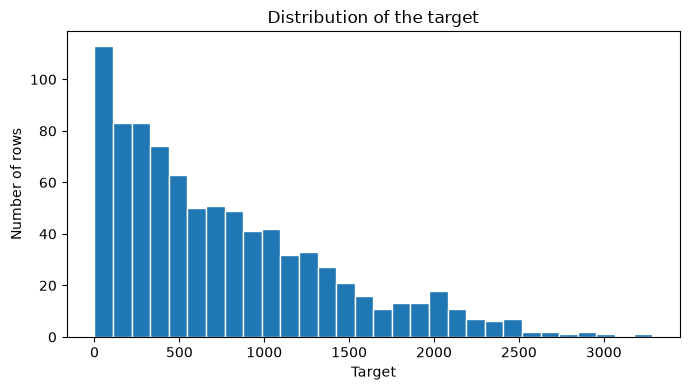

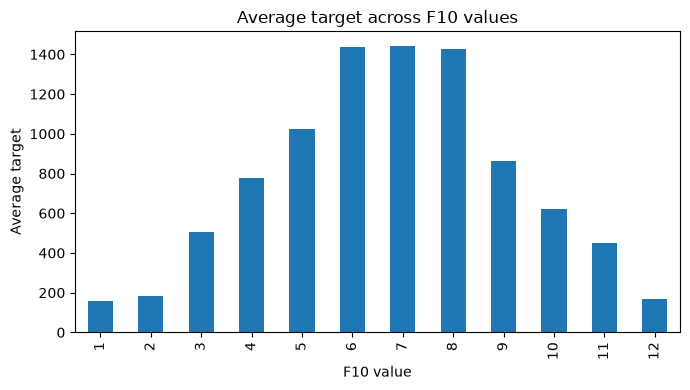

In [5]:
# YOUR CODE HERE

# First, check the size and basic quality of the data.
print("Data shape:", raw_df.shape)
print("Unique groups:", raw_df[GROUP_COLUMN].nunique())
print("Rows per group:")
display(raw_df.groupby(GROUP_COLUMN).size().describe().to_frame("rows_per_group"))

missing = pd.DataFrame({
    "data_type": raw_df.dtypes.astype(str),
    "missing_count": raw_df.isna().sum(),
    "missing_percent": (raw_df.isna().mean() * 100).round(2),
})
print("Column types and missing values:")
display(missing)

print("Target summary:")
display(raw_df[TARGET_COLUMN].describe().to_frame("target"))

# These summaries help show which features have noticeable relationships with target.
numeric = raw_df.select_dtypes(include=np.number)
correlations = numeric.corr()[TARGET_COLUMN].drop(TARGET_COLUMN).sort_values(
    key=lambda values: values.abs(), ascending=False
)
print("Numeric feature correlations with target:")
display(correlations.to_frame("correlation_with_target").round(3))

print("Average target by F10:")
display(raw_df.groupby("F10")[TARGET_COLUMN].agg(["count", "mean", "std"]).round(2))
print("Average target by F15:")
display(raw_df.groupby("F15")[TARGET_COLUMN].agg(["count", "mean", "std"]).round(2))

plt.figure(figsize=(7, 4))
plt.hist(raw_df[TARGET_COLUMN], bins=30, edgecolor="white")
plt.xlabel("Target")
plt.ylabel("Number of rows")
plt.title("Distribution of the target")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
raw_df.groupby("F10")[TARGET_COLUMN].mean().plot(kind="bar")
plt.xlabel("F10 value")
plt.ylabel("Average target")
plt.title("Average target across F10 values")
plt.tight_layout()
plt.show()


## 3. (8 points) Data Preparation and Feature Engineering

(a) **[4 point]** Based on the observations from your exploratory data analysis, prepare the dataset for modeling. Clearly explain the preprocessing and feature-
engineering decisions you make and how they are motivated by patterns or
issues identified during EDA. Only short bullet points are needed in the report,
not long explanations.

(b) **[1 point]** Evaluate whether your chosen data preparation and engineered
features are appropriate for modelling. Provide evidence for your choices and
discuss how you ensured that the resulting pipeline remains valid when applied
to previously unseen data

**A submission that fails part (a) or (b) also scores zero on the performance
parts of Questions 5 and 7.**

Model performance based parts are evaluated from rerunning code below, rest are evaluated from report

In [6]:
class Dataset:
    """Loads a CSV and exposes it as arrays ready for scikit-learn."""

    def __init__(self, filepath, preprocessor=None, do_fit=True):
        self.filepath = filepath
        self.preprocessor = preprocessor
        self.features = None
        self.labels = None
        self.groups = None
        self.feature_names = None
        self._load_and_preprocess(do_fit)

    def _load_and_preprocess(self, do_fit=True):
        """
        Load the CSV and preprocess it into arrays ready for scikit-learn.

        Args:
            do_fit (bool): Whether to fit the preprocessor on this data before
                applying it, or apply an already-fitted one.

        Sets:
            self.features (np.ndarray): Shape (n_samples, n_features), fully
                numeric, no missing values.
            self.labels (np.ndarray or None): Shape (n_samples,), or None if
                the file has no target column.
            self.groups (np.ndarray): Shape (n_samples,).
            self.preprocessor: Fitted, so it can be reused on unseen data.
            self.feature_names (list of str): One name per column of
                self.features.
        """
        # YOUR CODE HERE
        frame = pd.read_csv(self.filepath)
        self.labels = (pd.to_numeric(frame[TARGET_COLUMN], errors="coerce").to_numpy(dtype=float)
                       if TARGET_COLUMN in frame.columns else None)
        self.groups = (frame[GROUP_COLUMN].to_numpy() if GROUP_COLUMN in frame.columns
                       else np.arange(len(frame)))

        # IDs and group labels identify rows but should not become predictors.
        excluded = [TARGET_COLUMN, GROUP_COLUMN, ID_COLUMN]
        raw_features = frame.drop(columns=[column for column in excluded if column in frame.columns])

        if do_fit:
            numeric_columns = list(raw_features.select_dtypes(include=np.number).columns)
            categorical_columns = [column for column in raw_features.columns
                                   if column not in numeric_columns]
            numeric_data = raw_features.reindex(columns=numeric_columns).apply(
                pd.to_numeric, errors="coerce"
            )
            medians = numeric_data.median().fillna(0.0)
            imputed_numeric = numeric_data.fillna(medians)
            means = imputed_numeric.mean().fillna(0.0)
            scales = imputed_numeric.std(ddof=0).replace(0, 1.0).fillna(1.0)

            # Keep category levels from the fit data so unseen data gets the same columns.
            category_levels = {}
            for column in categorical_columns:
                values = raw_features[column].fillna("__MISSING__").astype(str)
                category_levels[column] = sorted(values.unique().tolist())

            self.preprocessor = {
                "numeric_columns": numeric_columns,
                "categorical_columns": categorical_columns,
                "medians": medians.to_dict(),
                "means": means.to_dict(),
                "scales": scales.to_dict(),
                "category_levels": category_levels,
            }

        prep = self.preprocessor
        numeric_columns = prep["numeric_columns"]
        categorical_columns = prep["categorical_columns"]
        numeric_data = raw_features.reindex(columns=numeric_columns).apply(
            pd.to_numeric, errors="coerce"
        )
        numeric_data = numeric_data.fillna(pd.Series(prep["medians"]))
        numeric_array = (
            (numeric_data - pd.Series(prep["means"])) / pd.Series(prep["scales"])
        ).to_numpy(dtype=float)

        categorical_arrays = []
        feature_names = list(numeric_columns)
        for column in categorical_columns:
            if column in raw_features.columns:
                values = raw_features[column].fillna("__MISSING__").astype(str)
            else:
                values = pd.Series(["__MISSING__"] * len(raw_features), index=raw_features.index)
            levels = prep["category_levels"][column]
            if levels:
                encoded = np.column_stack([
                    (values == level).to_numpy(dtype=float) for level in levels
                ])
            else:
                encoded = np.zeros((len(raw_features), 0))
            categorical_arrays.append(encoded)
            feature_names.extend([column + "=" + level for level in levels])

        # Squared standardized numeric features allow simple curvature without changing the model family.
        arrays = [numeric_array] + categorical_arrays + [numeric_array ** 2]
        feature_names.extend([column + "^2" for column in numeric_columns])
        self.features = np.column_stack(arrays).astype(float)
        self.features = np.nan_to_num(self.features, nan=0.0, posinf=0.0, neginf=0.0)
        self.feature_names = feature_names

    def get_features_and_labels(self):
        return self.features, self.labels

    def get_groups(self):
        return self.groups

In [7]:
# =======================
# DO NOT MODIFY THIS CELL
# =======================

train_dataset = Dataset(PATH_TO_TRAIN_FILE, do_fit=True)
X_train_full, y_train_full = train_dataset.get_features_and_labels()
print(f"train_dataset: X {X_train_full.shape}, y {y_train_full.shape}, "
      f"groups {len(set(train_dataset.get_groups()))}")

# Part (b): the same preparation, applied unchanged to rows it was not fit on.
# No separate file is provided for this -- a random held-out slice of your own
# training data, refit and re-applied here, is the check.
_check_rng = np.random.default_rng(ROLL_NUMBER)
_holdout_idx = _check_rng.choice(len(raw_df), size=max(10, len(raw_df) // 10), replace=False)
_fit_idx = np.setdiff1d(np.arange(len(raw_df)), _holdout_idx)
_probe_fit_path = "._q3_probe_fit.csv"
_probe_holdout_path = "._q3_probe_holdout.csv"
raw_df.iloc[_fit_idx].to_csv(_probe_fit_path, index=False)
raw_df.iloc[_holdout_idx].to_csv(_probe_holdout_path, index=False)

_probe_fit_dataset = Dataset(_probe_fit_path, do_fit=True)
_probe_holdout_dataset = Dataset(
    _probe_holdout_path, preprocessor=_probe_fit_dataset.preprocessor, do_fit=False
)
_X_holdout = _probe_holdout_dataset.get_features_and_labels()[0]

os.remove(_probe_fit_path)
os.remove(_probe_holdout_path)

assert _X_holdout.shape[1] == _probe_fit_dataset.get_features_and_labels()[0].shape[1], (
    "preparation produced a different number of columns on held-out rows"
)
assert not np.isnan(_X_holdout).any(), "held-out rows have missing values after preparation"
print("preparation generalizes to rows it was not fit on")

# Part (c): row identifiers and grouping information must not reach the model.
assert ID_COLUMN not in train_dataset.feature_names, f"{ID_COLUMN} leaked into the features"
assert not any(GROUP_COLUMN in name for name in train_dataset.feature_names), (
    f"{GROUP_COLUMN} leaked into the features"
)
print("identifier and group columns excluded from the features")

train_dataset: X (873, 46), y (873,), groups 291
preparation generalizes to rows it was not fit on
identifier and group columns excluded from the features


## 4. (3 points) Validation Strategy

(a) Split the training data into a training part and a validation
part.

In [8]:
def get_validation_split(dataset):
    """
    Split the training data into a training part and a validation part.

    Args:
        dataset (Dataset): The training dataset.

    Returns:
        tuple of np.ndarray: (train_idx, val_idx), integer row indices. Every
            row index must appear in exactly one of the two arrays.
    """
    train_idx, val_idx = None, None
    # YOUR CODE HERE

    rng = np.random.default_rng(ROLL_NUMBER)
    groups = np.asarray(dataset.get_groups())
    unique_groups = np.unique(groups)
    shuffled_groups = rng.permutation(unique_groups)

    selected_groups = []
    selected_rows = 0
    target_rows = int(np.ceil(0.20 * len(groups)))
    for group in shuffled_groups:
        selected_groups.append(group)
        selected_rows += int(np.sum(groups == group))
        if selected_rows >= target_rows:
            break

    val_mask = np.isin(groups, selected_groups)
    val_idx = np.flatnonzero(val_mask).astype(int)
    train_idx = np.flatnonzero(~val_mask).astype(int)

    # Refit imputation/scaling/category handling without using validation rows.
    frame = pd.read_csv(dataset.filepath)
    fit_path = "._q4_fit_training_rows.csv"
    try:
        frame.iloc[train_idx].to_csv(fit_path, index=False)
        fitted_dataset = Dataset(fit_path, do_fit=True)
        prepared_dataset = Dataset(
            dataset.filepath,
            preprocessor=fitted_dataset.preprocessor,
            do_fit=False,
        )
        dataset.preprocessor = prepared_dataset.preprocessor
        dataset.features = prepared_dataset.features
        dataset.feature_names = prepared_dataset.feature_names
    finally:
        if os.path.exists(fit_path):
            os.remove(fit_path)
    return train_idx, val_idx

In [9]:
# =======================
# DO NOT MODIFY THIS CELL
# =======================

train_idx, val_idx = get_validation_split(train_dataset)
assert len(set(train_idx) & set(val_idx)) == 0, "train and validation indices overlap"
assert len(train_idx) + len(val_idx) == len(y_train_full), "the split does not cover every row"
val_fraction = len(val_idx) / len(y_train_full)
assert 0.10 <= val_fraction <= 0.40, f"validation part is {val_fraction:.0%} of rows, outside 10-40%"
print(f"train rows: {len(train_idx)}, validation rows: {len(val_idx)} ({val_fraction:.0%})")

train rows: 696, validation rows: 177 (20%)


## 5. (6 points) Model Training and Evaluation

Your score here is computed twice: once in this question, and again in
Question 7 after you iterate on it. The two are graded separately.

(a) **[up to 4 points]** Train a linear regression model on your split. Scored
on a hidden test set:

| R² on hidden test set | Marks |
| :--------------------: | :---: |
| ≥ 0.90 | 4 |
| 0.85 to 0.90 | 3 |
| 0.75 to 0.85 | 2 |
| 0.65 to 0.75 | 1 |
| below 0.65 | 0 |

(b) **[2 points]** Justify your choice of model and hyperparameters. Before
looking at Question 6's diagnostics, say what you expect this choice to do to
the train and validation gap.

The cell below trains your model and reports its performance on your OWN
train/validation split -- use these numbers to decide what to submit. The
hidden-set score in the table above is computed separately after submission.

In [10]:
def get_regressor():
    """Return an unfitted sklearn.linear_model regressor with
    student-selected hyperparameters."""
    model = None
    # YOUR CODE HERE
    model = sklearn.linear_model.LinearRegression(fit_intercept=True)
    return model

In [11]:
# =======================
# DO NOT MODIFY THIS CELL
# =======================

class ModelTrainer:
    """Fits, evaluates and predicts with a scikit-learn regressor, taking
    Dataset objects directly."""

    def __init__(self, regressor):
        if not all(hasattr(regressor, attr) for attr in ("fit", "predict")):
            raise TypeError("The provided object is not a valid sklearn regressor.")
        self.regressor = regressor
        self.is_trained = False

    def train(self, dataset, indices=None):
        X, y = dataset.get_features_and_labels()
        if y is None:
            raise ValueError("Cannot train on a dataset with no labels.")
        if indices is not None:
            X, y = X[indices], y[indices]
        self.regressor.fit(X, y)
        self.is_trained = True
        return self

    def predict(self, dataset, indices=None):
        if not self.is_trained:
            raise ValueError("Regressor has not been trained. Call .train() first.")
        X, _ = dataset.get_features_and_labels()
        if indices is not None:
            X = X[indices]
        return np.clip(self.regressor.predict(X), 0, None)

    def evaluate(self, dataset, indices=None, title_prefix=""):
        y = dataset.get_features_and_labels()[1]
        if y is None:
            raise ValueError("Cannot evaluate on a dataset with no labels.")
        if indices is not None:
            y = y[indices]
        pred = self.predict(dataset, indices)

        scores = {
            "R2": r2_score(y, pred),
            "RMSE": mean_squared_error(y, pred) ** 0.5,
            "MAE": mean_absolute_error(y, pred),
        }
        header = f"{title_prefix} {self.regressor.__class__.__name__} Results".strip()
        print(header)
        print("-" * len(header))
        for key, value in scores.items():
            print(f"{key:5s}: {value:.4f}")
        return scores

In [12]:
# =======================
# DO NOT MODIFY THIS CELL
# =======================

trainer = ModelTrainer(get_regressor()).train(train_dataset, train_idx)
train_scores = trainer.evaluate(train_dataset, train_idx, title_prefix="[Train]")
print()
val_scores = trainer.evaluate(train_dataset, val_idx, title_prefix="[Validation]")

[Train] LinearRegression Results
--------------------------------
R2   : 0.8165
RMSE : 275.0503
MAE  : 206.4214

[Validation] LinearRegression Results
-------------------------------------
R2   : 0.7839
RMSE : 286.9598
MAE  : 216.7209


## 6. (6 points) Diagnostics

(a) **[2 points]** Produce diagnostics for your trained model: the gap between
train and validation performance, a learning curve for both, and the rows it
gets most wrong.

(b) **[2 points]** Look at the train and validation gap and the learning curve.
Say what they tell you about your model.

(c) **[2 points]** Look at the rows your model gets most wrong. Say what they
have in common, and what you would try next.

**Grading:** part (a) is graded by re-running the cell below -- it runs on the
model you already trained in Question 5, not a fresh one. Parts (b) and (c) are
graded from your report.

In [13]:
class Diagnostics:
    """Diagnostics for an already-trained model."""

    @staticmethod
    def bias_variance_report(trainer, dataset, train_idx, val_idx):
        """
        Report train and validation performance for a trained model.

        Args:
            trainer (ModelTrainer): An already-trained model.
            dataset (Dataset): The training dataset.
            train_idx, val_idx (np.ndarray): Row indices from Question 4.

        Returns:
            dict: {"train": scores, "validation": scores, "gap": float}, where
                "train"/"validation" are the dicts returned by
                trainer.evaluate(), and "gap" is train R2 minus validation R2.
        """
        result = None
        # YOUR CODE HERE
        train_scores = trainer.evaluate(dataset, train_idx, title_prefix="[Diagnostics: Train]")
        validation_scores = trainer.evaluate(dataset, val_idx, title_prefix="[Diagnostics: Validation]")
        result = {
            "train": train_scores,
            "validation": validation_scores,
            "gap": train_scores["R2"] - validation_scores["R2"],
        }
        print(f"Train-validation R2 gap: {result['gap']:.4f}")
        return result

    @staticmethod
    def learning_curve(dataset, train_idx, val_idx, regressor_factory,
                        fractions=(0.1, 0.25, 0.5, 0.75, 1.0)):
        """
        Train on increasing fractions of train_idx and report R2 on each
        fraction and on val_idx, so train/validation performance can be
        compared as training set size grows.

        Args:
            dataset (Dataset): The training dataset.
            train_idx, val_idx (np.ndarray): Row indices from Question 4.
            regressor_factory (callable): Returns a fresh unfitted regressor,
                e.g. get_regressor.
            fractions (tuple of float): Fractions of train_idx to train on.

        Returns:
            dict: {"sizes": [...], "train_r2": [...], "validation_r2": [...]},
                one entry per fraction, same order as `fractions`.
        """
        result = None
        # YOUR CODE HERE
        rng = np.random.default_rng(ROLL_NUMBER)
        train_groups = np.unique(dataset.groups[train_idx]).copy()
        rng.shuffle(train_groups)
        frame = pd.read_csv(dataset.filepath)
        sizes, train_r2, validation_r2 = [], [], []
        fit_path = "._q4_curve_fit_rows.csv"

        try:
            for fraction in fractions:
                group_count = max(1, min(len(train_groups), int(np.ceil(fraction * len(train_groups)))))
                selected = train_groups[:group_count]
                subset = np.asarray(train_idx)[np.isin(dataset.groups[train_idx], selected)]

                # Fit preprocessing only on the rows used at this point of the curve.
                frame.iloc[subset].to_csv(fit_path, index=False)
                fit_dataset = Dataset(fit_path, do_fit=True)
                view = Dataset(dataset.filepath, preprocessor=fit_dataset.preprocessor, do_fit=False)
                model = regressor_factory()
                model.fit(view.features[subset], view.labels[subset])

                train_prediction = np.clip(model.predict(view.features[subset]), 0, None)
                val_prediction = np.clip(model.predict(view.features[val_idx]), 0, None)
                sizes.append(len(subset))
                train_r2.append(r2_score(view.labels[subset], train_prediction))
                validation_r2.append(r2_score(view.labels[val_idx], val_prediction))
        finally:
            if os.path.exists(fit_path):
                os.remove(fit_path)

        result = {"sizes": sizes, "train_r2": train_r2, "validation_r2": validation_r2}
        plt.figure(figsize=(7, 4))
        plt.plot(sizes, train_r2, marker="o", label="Training R2")
        plt.plot(sizes, validation_r2, marker="o", label="Validation R2")
        plt.xlabel("Training rows (whole groups)")
        plt.ylabel("R2")
        plt.title("Learning curve")
        plt.legend()
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()
        print("Learning curve:", result)
        return result

    @staticmethod
    def error_analysis(trainer, dataset, val_idx, k=15):
        """
        Report the k validation rows the model gets most wrong.

        Args:
            trainer (ModelTrainer): An already-trained model.
            dataset (Dataset): The training dataset.
            val_idx (np.ndarray): Validation row indices from Question 4.
            k (int): Number of worst rows to report.

        Returns:
            pd.DataFrame: k rows sorted by absolute residual, descending, with
                columns row, group, y_true, y_pred, residual.
        """
        table = None
        # YOUR CODE HERE
        # Predict the validation rows and compare predictions with their true targets.
        rows = np.asarray(val_idx, dtype=int)
        _, labels = dataset.get_features_and_labels()
        predictions = trainer.predict(dataset, rows)
        residuals = labels[rows] - predictions
        raw_rows = pd.read_csv(dataset.filepath)

        row_labels = (raw_rows.iloc[rows][ID_COLUMN].astype(str).to_numpy()
                      if ID_COLUMN in raw_rows.columns else rows)
        table = pd.DataFrame({
            "row": row_labels,
            "group": dataset.get_groups()[rows],
            "y_true": labels[rows],
            "y_pred": predictions,
            "residual": residuals,
            "absolute_error": np.abs(residuals),
        })
        table = table.sort_values("absolute_error", ascending=False).head(k)
        table = table.drop(columns=["absolute_error"]).reset_index(drop=True)
        return table

[Diagnostics: Train] LinearRegression Results
---------------------------------------------
R2   : 0.8165
RMSE : 275.0503
MAE  : 206.4214
[Diagnostics: Validation] LinearRegression Results
--------------------------------------------------
R2   : 0.7839
RMSE : 286.9598
MAE  : 216.7209
Train-validation R2 gap: 0.0326


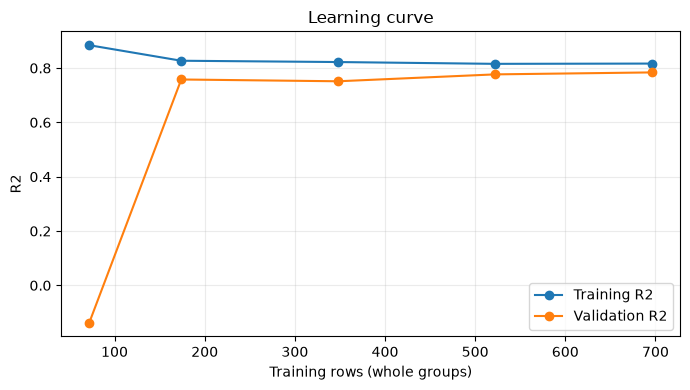

Learning curve: {'sizes': [72, 174, 348, 522, 696], 'train_r2': [0.884098937555176, 0.8268930677036519, 0.8221278661845547, 0.8154736889497937, 0.8164863634031343], 'validation_r2': [-0.1371379305548508, 0.757904738073286, 0.7513224723612241, 0.7766966403240073, 0.7839333036774832]}


In [14]:
# =======================
# DO NOT MODIFY THIS CELL
# =======================

# Runs on `trainer`, already trained in Question 5 -- nothing here retrains.
report = Diagnostics.bias_variance_report(trainer, train_dataset, train_idx, val_idx)
curve = Diagnostics.learning_curve(train_dataset, train_idx, val_idx, get_regressor)
errors = Diagnostics.error_analysis(trainer, train_dataset, val_idx)

## 7. (9 points) Model Improvement

(a) **[up to 4 points]** Take what you learned from Question 6 and change
something: your model, its hyperparameters, or how you are using your
features. Retrain. Scored on the same hidden test set as Question 5:

| R² on hidden test set | Marks |
| :--------------------: | :---: |
| ≥ 0.90 | 4 |
| 0.85 to 0.90 | 3 |
| 0.75 to 0.85 | 2 |
| 0.65 to 0.75 | 1 |
| below 0.65 | 0 |

(b) **[3 points]** Explain what you changed and why, based on your diagnostics.

(c) **[2 points]** Compare this score with Question 5's, and say whether the
change helped.

**Grading:** part (a) is graded by re-running the cell below. Parts (b) and (c)
are graded from your report.

**Student-level explanation of the improvement:**

- I kept the original numeric and one-hot encoded categorical features, including the squared numeric features created during preprocessing.
- I added simple interaction terms between F10 and the F13 category indicators, so F10 can have a different effect across F13 categories.
- I used Ridge Regression to keep coefficients under control. No spline features or tree-based model is used.
- The target is right-skewed, so I used a fourth-root transformation during training and reversed it when making predictions.


In [15]:
def get_improved_regressor():
    """Return a linear regressor using simple, explainable feature engineering."""
    # Keep the existing raw numeric and one-hot categorical features, including
    # the squared numeric columns already created in Dataset preprocessing.
    base_features = sklearn.compose.ColumnTransformer(
        transformers=[("existing_features", "passthrough", list(range(46)))],
        remainder="drop",
    )

    # Add only a simple interaction: F10 multiplied by each F13 category indicator.
    f10_f13_interactions = sklearn.pipeline.make_pipeline(
        sklearn.compose.ColumnTransformer(
            transformers=[
                ("F10", "passthrough", [9]),
                ("F13_categories", "passthrough", [16, 17, 18]),
            ],
            remainder="drop",
        ),
        sklearn.preprocessing.PolynomialFeatures(
            degree=2,
            interaction_only=True,
            include_bias=False,
        ),
    )

    combined_features = sklearn.pipeline.FeatureUnion(
        [
            ("existing_features", base_features),
            ("F10_F13_interactions", f10_f13_interactions),
        ]
    )

    linear_model = sklearn.pipeline.make_pipeline(
        combined_features,
        sklearn.preprocessing.StandardScaler(),
        sklearn.linear_model.Ridge(alpha=0.0001),
    )

    model = sklearn.compose.TransformedTargetRegressor(
        regressor=linear_model,
        func=lambda target: np.power(target, 0.25),
        inverse_func=lambda prediction: np.power(np.maximum(prediction, 0), 4),
    )
    return model

In [16]:
# =======================
# DO NOT MODIFY THIS CELL
# =======================

final_trainer = ModelTrainer(get_improved_regressor()).train(train_dataset, train_idx)
final_trainer.evaluate(train_dataset, train_idx, title_prefix="[Train]")
print()
final_trainer.evaluate(train_dataset, val_idx, title_prefix="[Validation]")

[Train] TransformedTargetRegressor Results
------------------------------------------
R2   : 0.8623
RMSE : 238.2215
MAE  : 163.0327

[Validation] TransformedTargetRegressor Results
-----------------------------------------------
R2   : 0.8363
RMSE : 249.8014
MAE  : 170.1736


{'R2': 0.8362672951439768,
 'RMSE': 249.80143823664122,
 'MAE': 170.17357416109647}

## 8. (3 points) Generalization and Limitations

(a) **[1 point]** The hidden test set contains groups you have never seen. Give
one concrete way your pipeline could still fail on them even with a good score.

(b) **[2 points]** Name one change you would try next, to the data, the
features, the model, or the validation strategy, and explain why you expect it
to help the most.

**Grading:** both parts are graded from your report. Nothing to run
here.